## Experiment 3 — Sampling Methods
**Dataset:** Housing Dataset (Real-Estate Pricing)  
**Objective:** Demonstrate three fundamental sampling strategies and compare their representativeness against the population mean.  
**Techniques:** Simple Random Sampling (SRS), Proportional Stratified Sampling, Cluster Sampling.

### 1. Setup & Imports
Import numpy, pandas, and matplotlib. Set a random seed to ensure reproducibility of all sampling operations.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

### 2. Load Dataset
Read the dataset and display its shape. Understanding the population size is necessary for choosing appropriate sample sizes.

In [2]:
df = pd.read_csv("Housing.csv")
print("Dataset shape:", df.shape)
print("Categorical columns:", df.select_dtypes(exclude=np.number).columns.tolist())
print("Numeric columns:", df.select_dtypes(include=np.number).columns.tolist())

Dataset shape: (545, 13)
Categorical columns: ['mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'prefarea', 'furnishingstatus']
Numeric columns: ['price', 'area', 'bedrooms', 'bathrooms', 'stories', 'parking']


### 3. Population Parameter
Compute the true population mean for the target variable. This serves as the benchmark against which the representativeness of each sampling method will be evaluated.

In [3]:
num_col = "price"
stratify_col = "bedrooms"
cluster_col = "furnishingstatus"

# Drop rows missing sampling columns
df = df.dropna(subset=[num_col, stratify_col, cluster_col]).reset_index(drop=True)

N = len(df)
n = max(1, int(0.20 * N))
population_mean = df[num_col].mean()
print(f"Population size N={N}, sample size n={n}, population mean of '{num_col}'={population_mean:.2f}")

Population size N=545, sample size n=109, population mean of 'price'=4766729.25


### 4. Simple Random Sampling (SRS)
Draw a random sample of fixed size without replacement from the full population. SRS gives every observation an equal probability of selection — the simplest unbiased estimator.

In [4]:
srs_sample = df.sample(n=n, random_state=42)
print("Simple Random Sample size:", len(srs_sample))
print(srs_sample.head())

Simple Random Sample size: 109
       price  area  bedrooms  bathrooms  stories mainroad guestroom basement  \
316  4060000  5900         4          2        2       no        no      yes   
77   6650000  6500         3          2        3      yes        no       no   
360  3710000  4040         2          1        1      yes        no       no   
90   6440000  5000         3          1        2      yes        no       no   
493  2800000  3960         3          1        1      yes        no       no   

    hotwaterheating airconditioning  parking prefarea furnishingstatus  
316              no              no        1       no      unfurnished  
77               no             yes        0      yes        furnished  
360              no              no        0       no   semi-furnished  
90               no             yes        0       no   semi-furnished  
493              no              no        0       no        furnished  


### 5. Proportional Stratified Sampling
Partition the population into homogeneous strata (e.g., by a categorical feature) and draw samples from each stratum proportional to its size. This guarantees representation of all subgroups and typically reduces sampling variance.

bedrooms
3    300
2    136
4     95
5     10
6      2
1      2
Name: count, dtype: int64


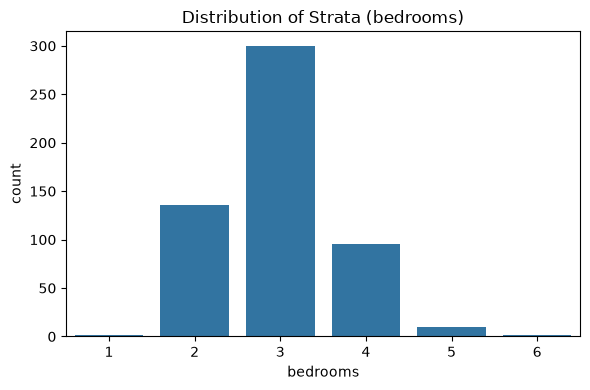

Stratified sample size: 110
          Population %  Sample %
bedrooms                        
3                55.05     54.55
2                24.95     24.55
4                17.43     17.27
5                 1.83      1.82
6                 0.37      0.91
1                 0.37      0.91


In [5]:
print(df[stratify_col].value_counts())
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x=stratify_col)
plt.title(f"Distribution of Strata ({stratify_col})")
plt.tight_layout()
plt.show()

# Proportional stratified sampling
parts = []
for grp, g in df.groupby(stratify_col, sort=False):
    k = max(1, round(len(g) * n / N))
    parts.append(g.sample(n=k, random_state=42))
strat_sample = pd.concat(parts).reset_index(drop=True)
print("Stratified sample size:", len(strat_sample))

strat_prop = pd.DataFrame({
    "Population %": df[stratify_col].value_counts(normalize=True) * 100,
    "Sample %": strat_sample[stratify_col].value_counts(normalize=True) * 100
}).round(2)
print(strat_prop)

### 6. Cluster Sampling
Divide the population into clusters, randomly select a subset of clusters, and include all observations from the chosen clusters. Cluster sampling reduces the cost of data collection when the population is geographically or logically grouped.

In [6]:
clusters = df[cluster_col].dropna().unique()
k = max(1, int(0.30 * len(clusters)))
rng = np.random.default_rng(42)
selected = rng.choice(clusters, size=k, replace=False)
print(f"Total clusters: {len(clusters)} | Selected clusters: {list(selected)}")

cluster_sample = df[df[cluster_col].isin(selected)].copy()
print("Cluster sample size:", len(cluster_sample))

Total clusters: 3 | Selected clusters: ['furnished']
Cluster sample size: 140


### 7. Comparison — Sample Means vs Population Mean
Compare the sample mean from each method against the true population mean to quantify representativeness. Smaller deviation indicates a more accurate estimate with the given sample size.

               Sample Size  Sample Mean  Difference from Population Mean
Simple Random          109   5007536.70                        240807.45
Stratified             110   4856310.45                         89581.21
Cluster                140   5495696.00                        728966.75


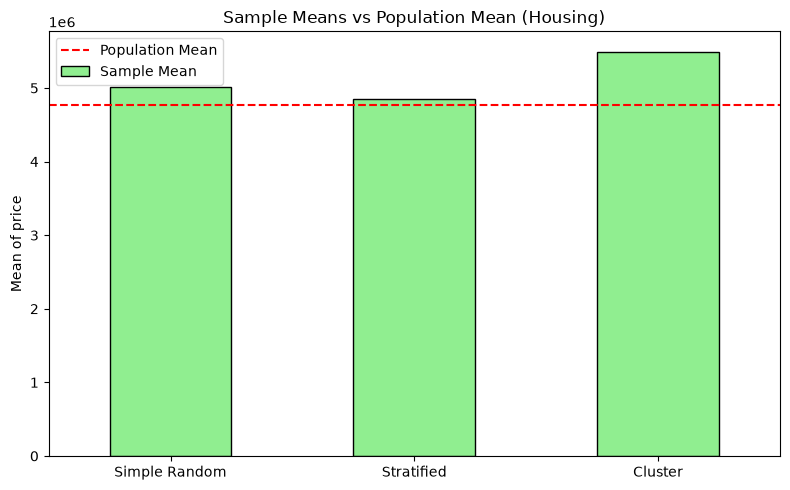

In [7]:
samples = {
    "Simple Random": srs_sample,
    "Stratified": strat_sample,
    "Cluster": cluster_sample
}

comparison = pd.DataFrame({
    "Sample Size": [len(s) for s in samples.values()],
    "Sample Mean": [s[num_col].mean() for s in samples.values()]
}, index=samples.keys())

comparison["Difference from Population Mean"] = comparison["Sample Mean"] - population_mean
print(comparison.round(2))

plt.figure(figsize=(8, 5))
comparison["Sample Mean"].plot(kind="bar", rot=0, color="lightgreen", edgecolor="black")
plt.axhline(population_mean, color="red", linestyle="--", label="Population Mean")
plt.ylabel(f"Mean of {num_col}")
plt.title("Sample Means vs Population Mean (Housing)")
plt.legend()
plt.tight_layout()
plt.show()

### 8. Save Samples
Export each sampled DataFrame to a CSV file for reference and downstream use.

In [8]:
srs_sample.to_csv("SRS_sample.csv", index=False)
strat_sample.to_csv("Stratified_sample.csv", index=False)
cluster_sample.to_csv("Cluster_sample.csv", index=False)
print("Saved sampling datasets to CSV files.")

Saved sampling datasets to CSV files.
